In [1]:
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('./data/clean.csv')

In [3]:
df.head()

,ConvertedCompYearly,Country,WorkExp,YearsCode,EdLevel,Age,DevType,Employment,OrgSize,RemoteWork,Industry,ICorPM,LanguageHaveWorkedWith
0,61256.0,Ukraine,8.0,14.0,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",25-34 years old,"Developer, mobile",Employed,20 to 99 employees,Remote,Fintech,People manager,Bash/Shell (all shells);Dart;SQL
1,104413.0,Netherlands,2.0,10.0,"Associate degree (A.A., A.S., etc.)",25-34 years old,"Developer, back-end",Employed,500 to 999 employees,"Hybrid (some in-person, leans heavy to flexibi...",Retail and Consumer Services,Individual contributor,Java
2,53061.0,Ukraine,10.0,12.0,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",35-44 years old,"Developer, front-end","Independent contractor, freelancer, or self-em...",Unknown,Unknown,Software Development,Unknown,Dart;HTML/CSS;JavaScript;TypeScript
3,36197.0,Ukraine,4.0,5.0,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",35-44 years old,"Developer, back-end",Employed,"10,000 or more employees",Remote,Retail and Consumer Services,Individual contributor,Java;Kotlin;SQL
4,60000.0,Ukraine,21.0,22.0,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",35-44 years old,Engineering manager,"Independent contractor, freelancer, or self-em...",Unknown,Unknown,Software Development,Unknown,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...


In [4]:
df.shape

(18857, 13)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18857 entries, 0 to 18856
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ConvertedCompYearly     18857 non-null  float64
 1   Country                 18857 non-null  str    
 2   WorkExp                 18857 non-null  float64
 3   YearsCode               18857 non-null  float64
 4   EdLevel                 18857 non-null  str    
 5   Age                     18857 non-null  str    
 6   DevType                 18857 non-null  str    
 7   Employment              18857 non-null  str    
 8   OrgSize                 18857 non-null  str    
 9   RemoteWork              18857 non-null  str    
 10  Industry                18857 non-null  str    
 11  ICorPM                  18857 non-null  str    
 12  LanguageHaveWorkedWith  18857 non-null  str    
dtypes: float64(3), str(10)
memory usage: 1.9 MB


In [9]:
df.isna().sum()

ConvertedCompYearly       0
Country                   0
WorkExp                   0
YearsCode                 0
EdLevel                   0
Age                       0
DevType                   0
Employment                0
OrgSize                   0
RemoteWork                0
Industry                  0
ICorPM                    0
LanguageHaveWorkedWith    0
dtype: int64

In [10]:
df.describe()

,ConvertedCompYearly,WorkExp,YearsCode
count,18857.000000,18857.000000,18857.000000
mean,94405.894204,13.432784,18.181312
std,67500.564872,9.638208,10.590943
min,1011.000000,1.000000,1.000000
25%,47334.000000,6.000000,10.000000
50%,81210.000000,11.000000,15.000000
75%,125296.000000,19.000000,25.000000
max,445000.000000,100.000000,100.000000


<Axes: >

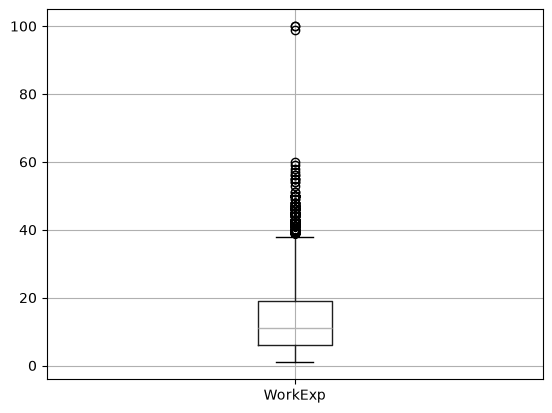

In [31]:
df.boxplot(column=['WorkExp'])

In [32]:
# Count rows where WorkExp is exactly 100
count_100 = (df['WorkExp'] == 100).sum()
print(count_100)

2


In [26]:
df['WorkExp'].value_counts().sort_values()
df['WorkExp'].max() # 100
df['WorkExp'].quantile([0.01, 0.25, 0.5, 0.75, 0.95, 0.99])


0.01     1.0
0.25     6.0
0.50    11.0
0.75    19.0
0.95    32.0
0.99    41.0
Name: WorkExp, dtype: float64

In [33]:
# Distribution of values above the 99th percentile
print(df[df['WorkExp'] > 41]['WorkExp'].value_counts().sort_index())

# How many are above 50?
print((df['WorkExp'] > 50).sum())

WorkExp
42.0     33
43.0     22
44.0      8
45.0     57
46.0     13
47.0     10
48.0      6
49.0      2
50.0     17
51.0      2
53.0      1
54.0      2
55.0      3
56.0      2
57.0      1
58.0      1
59.0      1
60.0      1
99.0      1
100.0     2
Name: count, dtype: int64
17


In [39]:
# Check how many rows would be removed
print((df['YearsCode'] > 60).sum(), "rows above 60")
print(df[df['YearsCode'] > 60]['YearsCode'].value_counts().sort_index())

# Apply the cutoff
df = df[df['YearsCode'] <= 60]

# Verify
print(df[['ConvertedCompYearly', 'WorkExp', 'YearsCode']].describe())

5 rows above 60
YearsCode
61.0     1
100.0    4
Name: count, dtype: int64
       ConvertedCompYearly       WorkExp     YearsCode
count          18852.00000  18852.000000  18852.000000
mean           94363.85174     13.417144     18.161680
std            67420.53881      9.571581     10.520442
min             1011.00000      1.000000      1.000000
25%            47334.00000      6.000000     10.000000
50%            81210.00000     11.000000     15.000000
75%           125296.00000     19.000000     25.000000
max           445000.00000     59.000000     60.000000


In [44]:
df_clean = df.loc[
    (df['WorkExp'] <= 52) &
    (df['YearsCode'] <= 60) &
    ((df['WorkExp'] - df['YearsCode']) <= 10)
].copy()
#print(len(df) - len(df_clean), "rows removed")
print(df_clean[['ConvertedCompYearly', 'WorkExp', 'YearsCode']].describe())

# Check how many fall between 50 and 52, to see if the choice matters
#print(df['WorkExp'].between(51, 52).sum())

       ConvertedCompYearly       WorkExp     YearsCode
count         18723.000000  18723.000000  18723.000000
mean          94333.231480     13.302569     18.182663
std           67501.741279      9.460794     10.492873
min            1011.000000      1.000000      1.000000
25%           47064.000000      6.000000     10.000000
50%           81210.000000     11.000000     15.000000
75%          125250.000000     19.000000     25.000000
max          445000.000000     51.000000     60.000000


In [46]:
df_clean.to_csv('./data/cleaned_data.csv', index=False)

In [47]:
df_clean.shape

(18723, 14)

In [11]:
df['ConvertedCompYearly'].value_counts().sort_index()

ConvertedCompYearly
1011.0      1
1018.0      1
1033.0      1
1042.0      1
1053.0      2
           ..
433975.0    1
440000.0    4
440856.0    2
444449.0    1
445000.0    1
Name: count, Length: 4859, dtype: int64

In [13]:
age_map = {
    '18-24 years old':    'Interns',
    '25-34 years old':    'Junior',
    '35-44 years old':    'Mid-Senior',
    '45-54 years old':    'Senior',
    '55-64 years old':    'Principal',
    '65 years or older':  'Super-Senior',
}

group_order = ['Interns', 'Junior', 'Mid-Senior', 'Senior', 'Principal', 'Super-Senior']

df['AgeGroup'] = pd.Categorical(df['Age'].map(age_map),
                                      categories=group_order, ordered=True)


In [15]:
df.head()

,ConvertedCompYearly,Country,WorkExp,YearsCode,EdLevel,Age,DevType,Employment,OrgSize,RemoteWork,Industry,ICorPM,LanguageHaveWorkedWith,AgeGroup
0,61256.0,Ukraine,8.0,14.0,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",25-34 years old,"Developer, mobile",Employed,20 to 99 employees,Remote,Fintech,People manager,Bash/Shell (all shells);Dart;SQL,Junior
1,104413.0,Netherlands,2.0,10.0,"Associate degree (A.A., A.S., etc.)",25-34 years old,"Developer, back-end",Employed,500 to 999 employees,"Hybrid (some in-person, leans heavy to flexibi...",Retail and Consumer Services,Individual contributor,Java,Junior
2,53061.0,Ukraine,10.0,12.0,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",35-44 years old,"Developer, front-end","Independent contractor, freelancer, or self-em...",Unknown,Unknown,Software Development,Unknown,Dart;HTML/CSS;JavaScript;TypeScript,Mid-Senior
3,36197.0,Ukraine,4.0,5.0,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",35-44 years old,"Developer, back-end",Employed,"10,000 or more employees",Remote,Retail and Consumer Services,Individual contributor,Java;Kotlin;SQL,Mid-Senior
4,60000.0,Ukraine,21.0,22.0,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",35-44 years old,Engineering manager,"Independent contractor, freelancer, or self-em...",Unknown,Unknown,Software Development,Unknown,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...,Mid-Senior


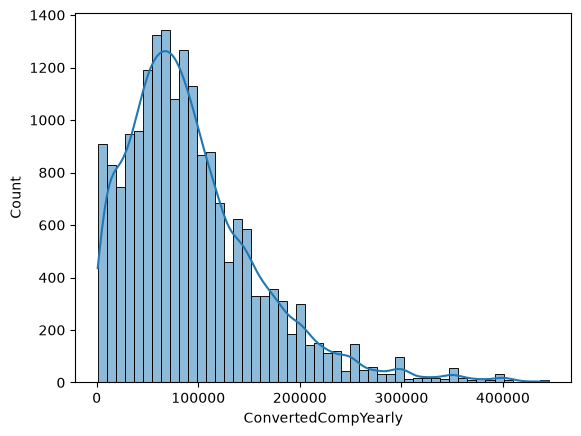

In [17]:
sns.histplot(df['ConvertedCompYearly'], bins=50, kde=True)
plt.show()

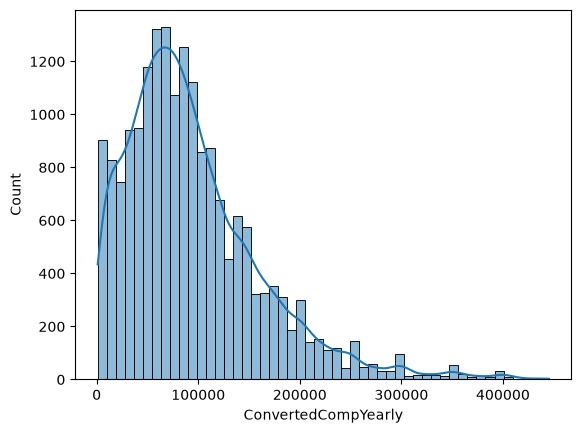

In [48]:
sns.histplot(df_clean['ConvertedCompYearly'], bins=50, kde=True)
plt.show()

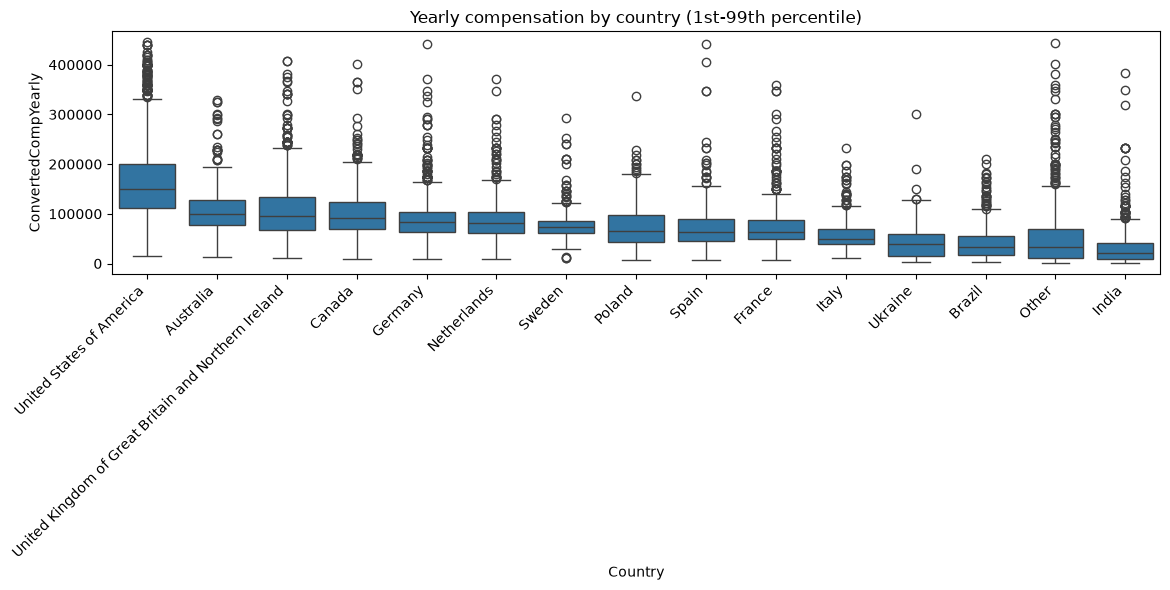

In [18]:
# top 10 countries by number of respondents
top_countries = df['Country'].value_counts().head(15).index
df_top = df[df['Country'].isin(top_countries)]

# order by median salary
order = (df_top.groupby('Country')['ConvertedCompYearly']
               .median().sort_values(ascending=False).index)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='Country', y='ConvertedCompYearly', order=order)
plt.xticks(rotation=45, ha='right')
plt.title('Yearly compensation by country (1st-99th percentile)')
plt.tight_layout()
plt.show()

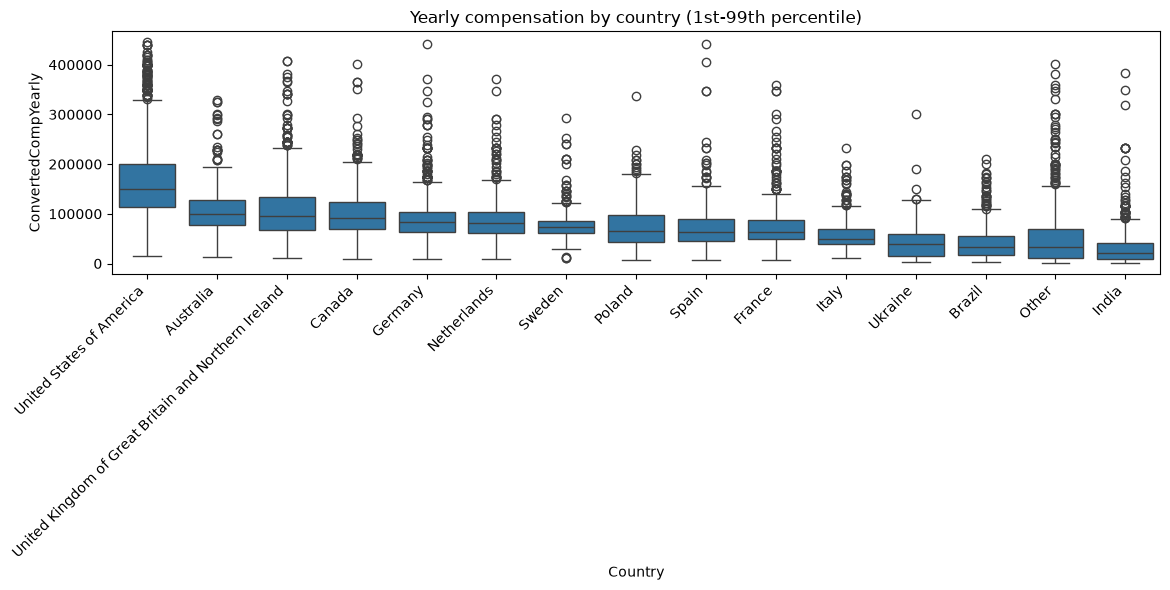

In [49]:
top_countries = df_clean['Country'].value_counts().head(15).index
df_top = df_clean[df_clean['Country'].isin(top_countries)]

# order by median salary
order = (df_top.groupby('Country')['ConvertedCompYearly']
               .median().sort_values(ascending=False).index)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='Country', y='ConvertedCompYearly', order=order)
plt.xticks(rotation=45, ha='right')
plt.title('Yearly compensation by country (1st-99th percentile)')
plt.tight_layout()
plt.show()

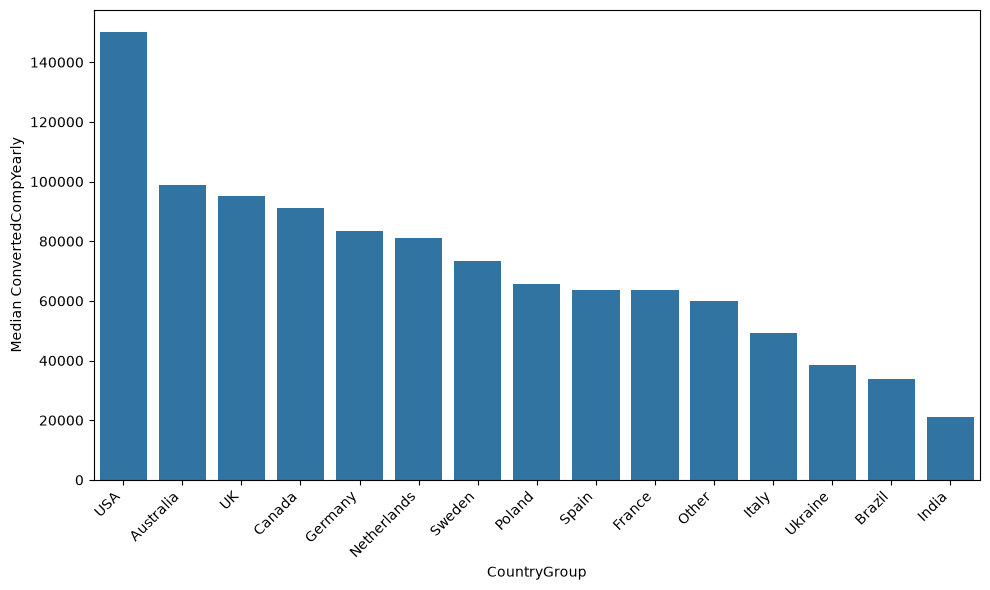

In [19]:
df_g = df.copy()

# keep the top N countries, group everything else as "Other"
top = df_g['Country'].value_counts().head(15).index
df_g['CountryGroup'] = df_g['Country'].where(df_g['Country'].isin(top), 'Other')

# shorten long names
df_g['CountryGroup'] = df_g['CountryGroup'].replace({
    'United States of America': 'USA',
    'United Kingdom of Great Britain and Northern Ireland': 'UK',
})

order = (df_g.groupby('CountryGroup')['ConvertedCompYearly']
             .median().sort_values(ascending=False).index)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_g, x='CountryGroup', y='ConvertedCompYearly',
            order=order, estimator='median', errorbar=None)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Median ConvertedCompYearly')
plt.tight_layout()
plt.show()

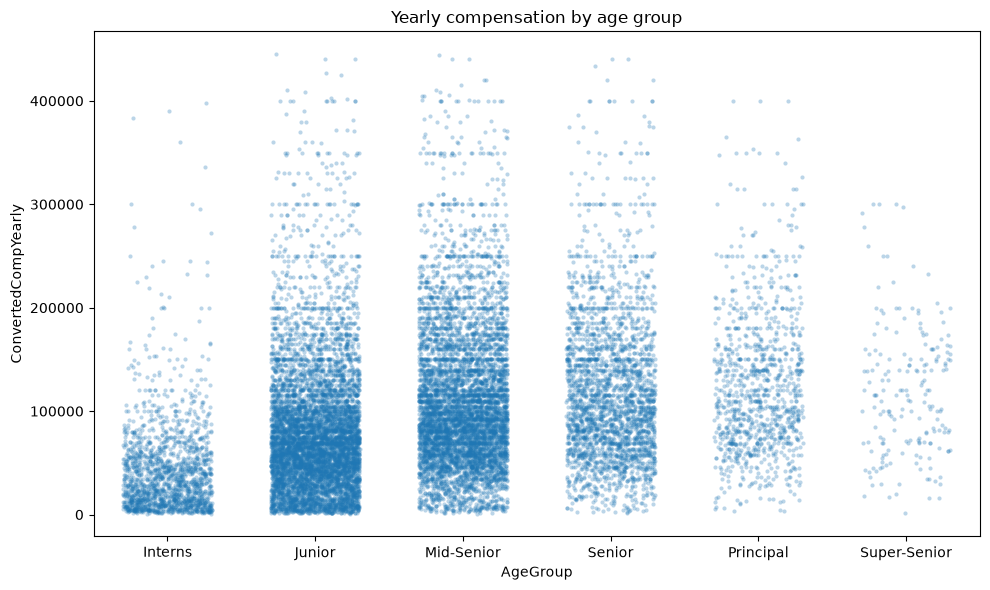

In [20]:
group_order = ['Interns', 'Junior', 'Mid-Senior', 'Senior', 'Principal', 'Super-Senior']
plt.figure(figsize=(10, 6))
sns.stripplot(data=df, x='AgeGroup', y='ConvertedCompYearly',
              order=group_order, size=3, alpha=0.3, jitter=0.3)
plt.title('Yearly compensation by age group')
plt.tight_layout()
plt.show()

In [51]:
# Only categorical (object/string) columns
df_clean.describe(include='object')

# Or explicitly with the category dtype too
df_clean.describe(include=['object', 'category'])

# All columns, numeric and categorical together
df_clean.describe(include='all')

/var/folders/7q/hg2_dwc17jng9c7169fzwrb80000gn/T/ipykernel_4774/576311462.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_clean.describe(include='object')
/var/folders/7q/hg2_dwc17jng9c7169fzwrb80000gn/T/ipykernel_4774/576311462.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user

,ConvertedCompYearly,Country,WorkExp,YearsCode,EdLevel,Age,DevType,Employment,OrgSize,RemoteWork,Industry,ICorPM,LanguageHaveWorkedWith,AgeGroup
count,18723.000000,18723,18723.000000,18723.000000,18723,18723,18723,18723,18723,18723,18723,18723,18723,18711
unique,NaN,50,NaN,NaN,8,7,32,6,10,6,16,3,9006,6
top,NaN,United States of America,NaN,NaN,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",25-34 years old,"Developer, full-stack",Employed,20 to 99 employees,Remote,Software Development,Individual contributor,Unknown,Junior
freq,NaN,4073,NaN,NaN,8546,7114,6815,15809,3596,6004,9246,14453,1165,7114
mean,94333.231480,NaN,13.302569,18.182663,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,67501.741279,NaN,9.460794,10.492873,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1011.000000,NaN,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,47064.000000,NaN,6.000000,10.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,81210.000000,NaN,11.000000,15.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,125250.000000,NaN,19.000000,25.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
df_clean[df_clean['AgeGroup'].isna()]['Age'].value_counts()

Age
Prefer not to say    12
Name: count, dtype: int64